# Fid+ vs ground-truth accuracy (synthetic targets)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.stats import kendalltau, spearmanr

from mol_faith.notebooks.results_analysis.shared import (
    SYNTHETIC_RESULTS,
    SYNTHETIC_TARGETS,
    calculate_total_atoms,
    extract_gt_atoms_number,
    load_raw_data,
    load_raw_gt_data,
    process_fidelity_df,
)

OUTPUT_DIR = SYNTHETIC_RESULTS / 'result_plots' / 'fid_vs_gt'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load data

In [2]:
fid_data = {target_name: process_fidelity_df(load_raw_data(SYNTHETIC_RESULTS / folder, target_name))
            for folder, target_name in SYNTHETIC_TARGETS.values()}
gt_data = {target_name: load_raw_gt_data(SYNTHETIC_RESULTS / folder, target_name)
           for folder, target_name in SYNTHETIC_TARGETS.values()}

benzene: 237,635 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
203,135 rows | {'faithful': 149075, 'unfaithful': 54060} | normalized_fid in [-1.000, 1.000]


conjugated_system: 240,471 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
205,971 rows | {'faithful': 154068, 'unfaithful': 51903} | normalized_fid in [-1.000, 1.000]


hbond_donor: 239,135 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
204,635 rows | {'faithful': 174450, 'unfaithful': 30185} | normalized_fid in [-1.000, 1.000]


benzene: 131,014 rows | targets ['benzene'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling']


conjugated_system: 227,149 rows | targets ['largest_conjugated_system'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling']


hbond_donor: 153,120 rows | targets ['hbond_donor'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling']


## Merge Fid+ with GT accuracy

In [3]:
def merge_fidelity_gt(fid_df, gt_df):
    match_cols = ['target_name', 'model', 'smiles', 'data_split_idx', 'target', 'explanation_method']
    merge_cols = ['smiles', 'model', 'explanation_method', 'data_split_idx', 'target']
    fid_df = fid_df.merge(gt_df[match_cols].drop_duplicates(), on=match_cols)
    merged = fid_df.drop_duplicates(merge_cols).merge(gt_df.drop_duplicates(merge_cols), on=merge_cols,
                                                      suffixes=('', '_gt'))
    print(f'{fid_df["target_name"].iat[0]}: {len(merged):,} merged rows, {merged["smiles"].nunique():,} molecules')
    return merged[['model', 'smiles', 'data_split_idx', 'target', 'explanation_method', 'fid_plus', 'fid_plus_random',
                   'normalized_fid', 'metadata_target_fraction', 'metadata_precision_at_k_gt']]


gt_fid_data = {name: merge_fidelity_gt(fid_data[name], gt_data[name]) for name in fid_data}

benzene: 112,289 merged rows, 3,039 molecules


conjugated_system: 194,624 merged rows, 5,388 molecules


hbond_donor: 131,245 merged rows, 3,560 molecules


## Correlation Fid+ vs GT accuracy

In [4]:
def spearman_ci(rho, n, alpha=0.05):
    z, se = np.arctanh(rho), 1 / np.sqrt(n - 3)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    return np.tanh(z - z_crit * se), np.tanh(z + z_crit * se)


def kendall_ci(tau, n, alpha=0.05):
    if np.isnan(tau):
        return np.nan, np.nan
    se = np.sqrt(2 * (2 * n + 5) / (9 * n * (n - 1)))
    z_crit = stats.norm.ppf(1 - alpha / 2)
    return max(-1, tau - z_crit * se), min(1, tau + z_crit * se)


def analyze_correlations_by_model_xai(df):
    rows = []
    for (model, method), group in df.groupby(['model', 'explanation_method']):
        group = group[['normalized_fid', 'metadata_target_fraction']].dropna()
        n = len(group)
        if n < 3:
            continue
        rho, rho_p = spearmanr(group['normalized_fid'], group['metadata_target_fraction'])
        tau, tau_p = kendalltau(group['normalized_fid'], group['metadata_target_fraction'])
        (rho_lo, rho_hi), (tau_lo, tau_hi) = spearman_ci(rho, n), kendall_ci(tau, n)
        rows.append({
            'model_xai_combination': f'{model}_{method}', 'model': model, 'explanation_method': method,
            'n_samples': n, 'spearman_correlation': rho, 'spearman_p_value': rho_p, 'spearman_ci_lower': rho_lo,
            'spearman_ci_upper': rho_hi, 'kendall_correlation': tau, 'kendall_p_value': tau_p,
            'kendall_ci_lower': tau_lo, 'kendall_ci_upper': tau_hi,
        })
    results = pd.DataFrame(rows)
    for prefix in ('spearman', 'kendall'):
        p = results[f'{prefix}_p_value']
        results[f'{prefix}_significant_05'] = p < 0.05
        results[f'{prefix}_significant_01'] = p < 0.01
        results[f'{prefix}_p_bonferroni'] = np.minimum(p * len(results), 1.0)
        results[f'{prefix}_significant_05_bonferroni'] = results[f'{prefix}_p_bonferroni'] < 0.05
    return results


heatmap_labels = {'benzene': 'Benzene', 'conjugated_system': 'Conjugated System', 'hbond_donor': 'Hbond-Donor'}
correlation_results = pd.concat(
    {heatmap_labels[name]: analyze_correlations_by_model_xai(df) for name, df in gt_fid_data.items()},
    names=['target'],
).reset_index(level=0)
correlation_results

,target,model_xai_combination,model,explanation_method,n_samples,spearman_correlation,spearman_p_value,spearman_ci_lower,spearman_ci_upper,kendall_correlation,...,kendall_ci_lower,kendall_ci_upper,spearman_significant_05,spearman_significant_01,spearman_p_bonferroni,spearman_significant_05_bonferroni,kendall_significant_05,kendall_significant_01,kendall_p_bonferroni,kendall_significant_05_bonferroni
0,Benzene,CNN_grad_cam,CNN,grad_cam,3745,-0.022188,1.746024e-01,-0.054179,0.009848,-0.014609,...,-0.035970,0.006753,False,False,1.000000e+00,False,False,False,1.000000e+00,False
1,Benzene,CNN_guided_grad_cam,CNN,guided_grad_cam,3745,0.080814,7.345453e-07,0.048912,0.112552,0.054337,...,0.032975,0.075698,True,True,2.203636e-05,True,True,True,1.854064e-05,True
2,Benzene,CNN_integrated_gradients,CNN,integrated_gradients,3745,-0.027654,9.063124e-02,-0.059630,0.004379,-0.017297,...,-0.038658,0.004065,False,False,1.000000e+00,False,False,False,1.000000e+00,False
3,Benzene,CNN_kernel_shap,CNN,kernel_shap,3745,0.026803,1.010094e-01,-0.005231,0.058782,0.017747,...,-0.003614,0.039109,False,False,1.000000e+00,False,False,False,1.000000e+00,False
4,Benzene,CNN_lime,CNN,lime,3745,0.000920,9.551257e-01,-0.031110,0.032948,0.000485,...,-0.020876,0.021847,False,False,1.000000e+00,False,False,False,1.000000e+00,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25,Hbond-Donor,GIN_shap_sampling,GIN,shap_sampling,4375,0.063302,2.788873e-05,0.033732,0.092762,0.043972,...,0.024210,0.063735,True,True,8.366619e-04,True,True,True,3.884036e-04,True
26,Hbond-Donor,Transformer_integrated_gradients,Transformer,integrated_gradients,4375,0.238280,1.573802e-57,0.210130,0.266035,0.159292,...,0.139530,0.179055,True,True,4.721407e-56,True,True,True,9.645712e-55,True
27,Hbond-Donor,Transformer_kernel_shap,Transformer,kernel_shap,4375,0.284700,2.286840e-82,0.257237,0.311704,0.190993,...,0.171231,0.210756,True,True,6.860519e-81,True,True,True,1.550811e-78,True
28,Hbond-Donor,Transformer_lime,Transformer,lime,4375,0.237340,4.449714e-57,0.209178,0.265109,0.159987,...,0.140224,0.179749,True,True,1.334914e-55,True,True,True,3.230164e-55,True


Comprehensive Bonferroni correction for 90 tests


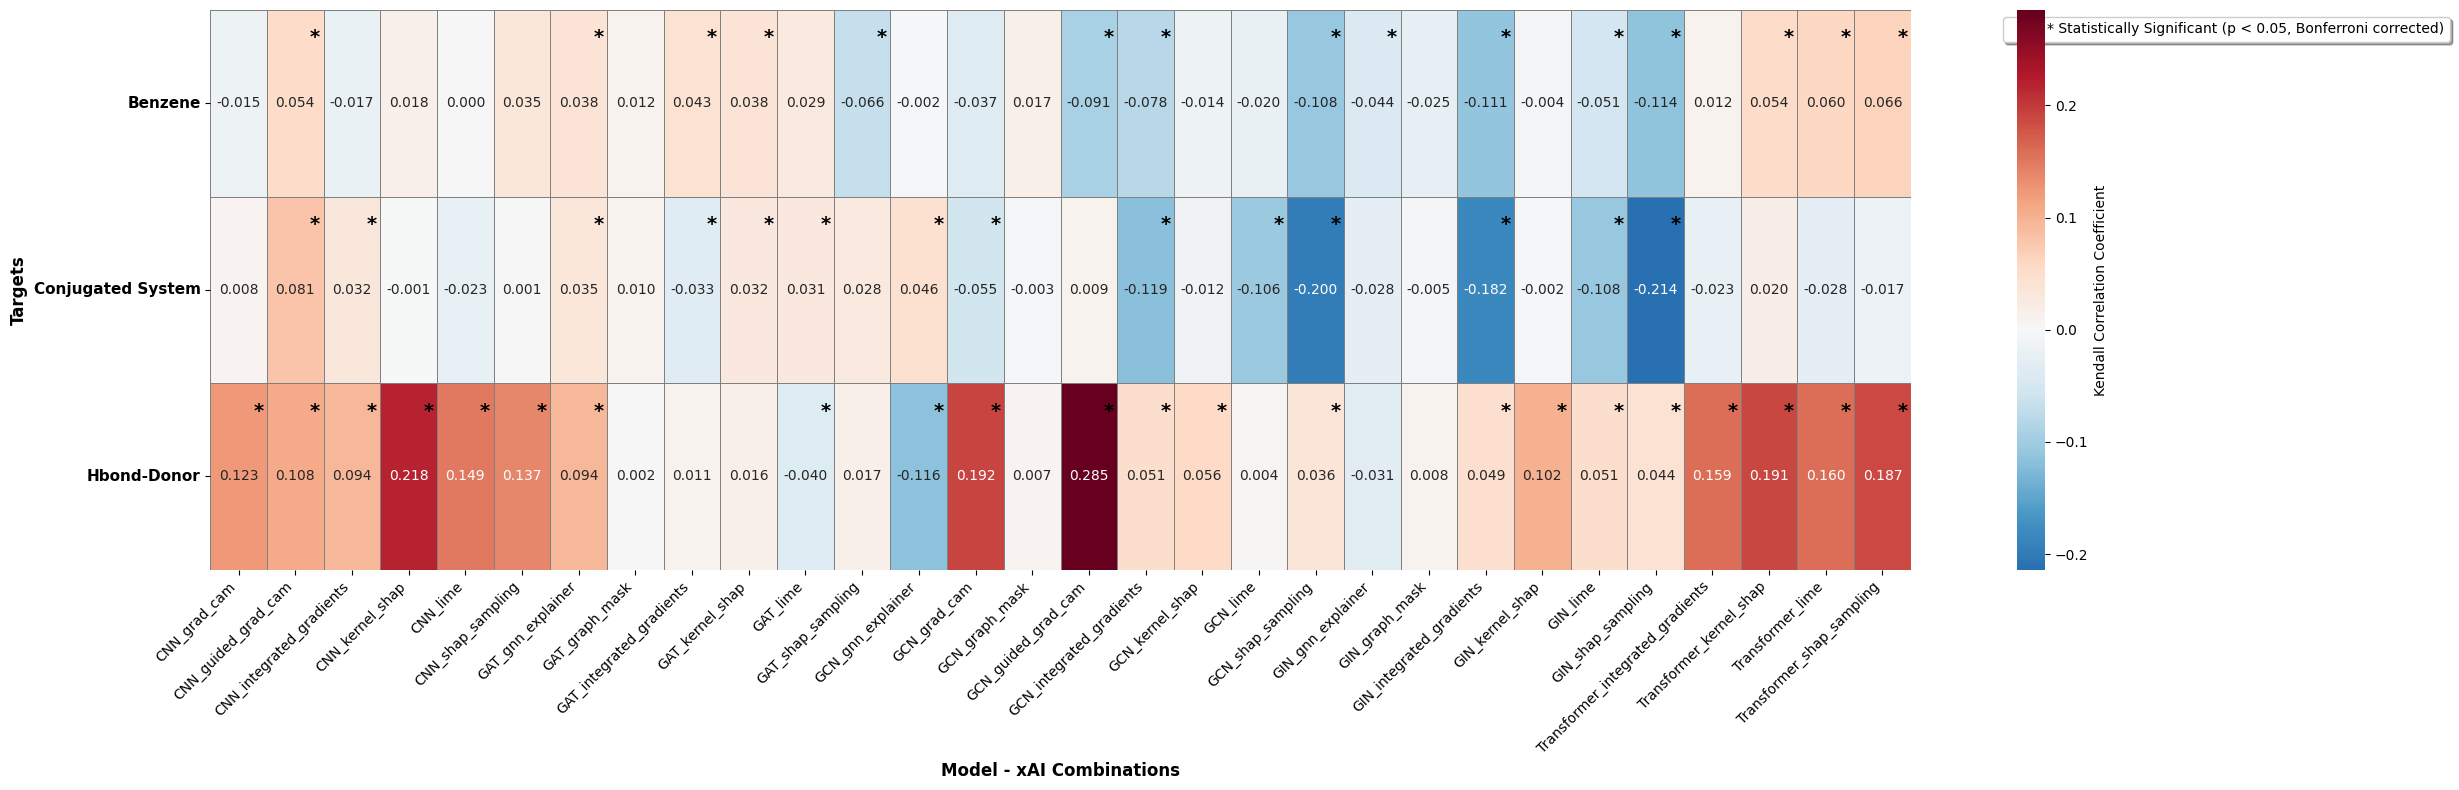

In [5]:
def pivot_by_target(values):
    return correlation_results.pivot(index='target', columns='model_xai_combination', values=values).reindex(
        list(heatmap_labels.values()))


kendall_matrix = pivot_by_target('kendall_correlation')
n_tests = kendall_matrix.size
print(f'Comprehensive Bonferroni correction for {n_tests} tests')
significance_matrix = np.minimum(pivot_by_target('kendall_p_value') * n_tests, 1.0) < 0.05

fig, ax = plt.subplots(figsize=(25, 8), facecolor='white')
sns.heatmap(kendall_matrix, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            cbar_kws={'label': 'Kendall Correlation Coefficient'}, linewidths=0.5, linecolor='gray',
            annot_kws={'fontsize': 10}, ax=ax)
for i, j in zip(*np.nonzero(significance_matrix.values)):
    ax.text(j + 0.85, i + 0.15, '*', ha='center', va='center', color='black', fontsize=14, fontweight='bold')
ax.set_xlabel('Model - xAI Combinations', fontsize=12, fontweight='bold')
ax.set_ylabel('Targets', fontsize=12, fontweight='bold')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=10)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=11, fontweight='bold')
ax.legend(handles=[plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='black', markersize=10,
                              label='* Statistically Significant (p < 0.05, Bonferroni corrected)')],
          loc='upper left', bbox_to_anchor=(1.05, 1), frameon=True, fancybox=True, shadow=True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'heatmap.svg', dpi=300, bbox_inches='tight', facecolor='white')

### Per xAI method

Bonferroni correction applied for 24 tests.


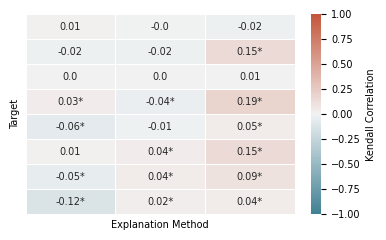

In [6]:
def kendall_by_method(df):
    rows = {}
    for method, group in df.groupby('explanation_method', sort=False):
        group = group[['normalized_fid', 'metadata_target_fraction']].dropna()
        if len(group) >= 3:
            tau, p = kendalltau(group['normalized_fid'], group['metadata_target_fraction'])
            rows[method] = {'kendall_correlation': tau, 'kendall_p_value': p, 'n_samples': len(group)}
    return pd.DataFrame.from_dict(rows, orient='index')


method_results = {heatmap_labels[name]: kendall_by_method(gt_fid_data[name])
                  for name in ('conjugated_system', 'benzene', 'hbond_donor')}
corr_df = pd.DataFrame({target: df['kendall_correlation'] for target, df in method_results.items()})
p_df = pd.DataFrame({target: df['kendall_p_value'] for target, df in method_results.items()})
n_tests = p_df.notna().sum().sum()
print(f'Bonferroni correction applied for {n_tests} tests.')
annot = corr_df.round(2).astype(str) + (p_df < 0.05 / n_tests).map(lambda significant: '*' if significant else '')

plt.figure(figsize=(4, 2.5))
ax = sns.heatmap(corr_df, annot=annot, fmt='', cmap=sns.diverging_palette(220, 20, as_cmap=True), center=0,
                 vmin=-1, vmax=1, linewidths=0.5, linecolor='white', cbar_kws={'label': 'Kendall Correlation'},
                 annot_kws={'size': 7})
plt.xlabel('Explanation Method', fontsize=7)
plt.ylabel('Target', fontsize=7)
plt.xticks([])
plt.yticks([])
ax.collections[0].colorbar.ax.tick_params(labelsize=7)
ax.collections[0].colorbar.set_label('Kendall Correlation', size=7)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'correlation_heatmap.svg', dpi=300)
plt.show()

## Correlation with GT size

In [7]:
def molecule_sizes(df, target_name):
    smiles = df['smiles'].unique()
    total = pd.Series({s: calculate_total_atoms(s) for s in smiles})
    gt = pd.Series({s: extract_gt_atoms_number(s, target_name) for s in smiles})
    return pd.DataFrame({'total_atoms': total, 'gt_count': gt, 'gt_fraction': gt / total})


sizes = {name: molecule_sizes(df, name) for name, df in gt_fid_data.items()}
for label, (_, name) in SYNTHETIC_TARGETS.items():
    df = gt_fid_data[name]
    gt_fraction = df['smiles'].map(sizes[name]['gt_fraction'])
    print(f"{label}: Kendall(normalized Fid+, GT atom fraction) = "
          f"{df['normalized_fid'].corr(gt_fraction, method='kendall'):.4f} | "
          f"Kendall(GT accuracy, GT atom fraction) = "
          f"{df['metadata_target_fraction'].corr(gt_fraction, method='kendall'):.4f}")

Benzene: Kendall(normalized Fid+, GT atom fraction) = -0.0156 | Kendall(GT accuracy, GT atom fraction) = 0.5090
Conjugated System: Kendall(normalized Fid+, GT atom fraction) = -0.0234 | Kendall(GT accuracy, GT atom fraction) = 0.7631
Hbond Donor: Kendall(normalized Fid+, GT atom fraction) = 0.0016 | Kendall(GT accuracy, GT atom fraction) = 0.3585


## GT accuracy vs Fid+ mismatches

`robust`: high GT accuracy (>= 75th percentile) with low Fid+ (<= 25th percentile). `shortcut`: low GT accuracy (<= 25th percentile) with high Fid+ (>= 75th percentile). Percentiles are computed within each model + xAI method combination with at least 50 samples; the 50 largest deviations per combination are kept as examples.

In [8]:
def analyze_gt_fid_mismatch(df, sizes, pattern, low_percentile=25, high_percentile=75, min_samples=50,
                            n_examples=50):
    df = df.join(sizes, on='smiles')
    results, examples = [], []
    for (model, method), group in df.groupby(['model', 'explanation_method']):
        if len(group) < min_samples:
            continue
        gt, fid = group['metadata_target_fraction'], group['fid_plus']
        if pattern == 'robust':
            gt_threshold, fid_threshold = gt.quantile(high_percentile / 100), fid.quantile(low_percentile / 100)
            mask, deviation = (gt >= gt_threshold) & (fid <= fid_threshold), gt - fid
        else:
            gt_threshold, fid_threshold = gt.quantile(low_percentile / 100), fid.quantile(high_percentile / 100)
            mask, deviation = (gt <= gt_threshold) & (fid >= fid_threshold), fid - gt
        cases = group[mask].assign(deviation_score=deviation[mask])
        examples.append(cases.nlargest(n_examples, 'deviation_score').assign(
            gt_target_fraction=lambda d: d['metadata_target_fraction'], gt_threshold=gt_threshold,
            fid_threshold=fid_threshold))
        results.append({
            'model': model, 'explanation_method': method, 'n_samples': len(group),
            'gt_threshold_used': gt_threshold, 'fid_threshold_used': fid_threshold,
            f'n_{pattern}_learning_cases': mask.sum(), f'pct_{pattern}_learning': mask.mean() * 100,
            'mean_gt': gt.mean(), 'mean_fid_plus': fid.mean(),
            'mean_fid_plus_random': group['fid_plus_random'].mean(),
            'mean_normalized_fid': group['normalized_fid'].mean(),
            'correlation_gt_fid': gt.corr(group['normalized_fid']),
            f'avg_gt_in_{pattern}_cases': cases['metadata_target_fraction'].mean(),
            f'avg_normalized_fid_in_{pattern}_cases': cases['normalized_fid'].mean(),
            f'avg_total_atoms_in_{pattern}_cases': cases['total_atoms'].mean(),
            f'std_total_atoms_in_{pattern}_cases': cases['total_atoms'].std(),
            f'avg_gt_fraction_in_{pattern}_cases': cases['gt_fraction'].mean(),
            f'std_gt_fraction_in_{pattern}_cases': cases['gt_fraction'].std(),
        })
    return (pd.DataFrame(results).sort_values(f'pct_{pattern}_learning', ascending=False),
            pd.concat(examples, ignore_index=True))


def summarize_mismatch(results, examples, pattern):
    n_cases = results[f'n_{pattern}_learning_cases'].sum()
    return pd.Series({
        'median accuracy': results[f'avg_gt_in_{pattern}_cases'].median(),
        'median GT fraction': results[f'avg_gt_fraction_in_{pattern}_cases'].median(),
        'extreme cases GT fraction': examples['gt_fraction'].median(),
        'extreme cases accuracy': examples['gt_target_fraction'].median(),
        'extreme cases total atoms': examples['total_atoms'].median(),
        'extreme cases normalized Fid+': examples['normalized_fid'].median(),
        'extreme cases Fid+': examples['fid_plus'].median(),
        'total cases': n_cases,
        'fraction of cases': n_cases / results['n_samples'].sum(),
        'median of mean total atoms': np.around(results[f'avg_total_atoms_in_{pattern}_cases'].median(), 2),
        'median of std total atoms': np.around(results[f'std_total_atoms_in_{pattern}_cases'].median(), 2),
    })


mismatches = {(label, pattern): analyze_gt_fid_mismatch(gt_fid_data[name], sizes[name], pattern)
              for label, (_, name) in SYNTHETIC_TARGETS.items() for pattern in ('robust', 'shortcut')}
pd.DataFrame({key: summarize_mismatch(*result, key[1]) for key, result in mismatches.items()})

Benzene              Conjugated System  \
                                    robust     shortcut            robust   
median accuracy                   0.652514     0.250614          0.925651   
median GT fraction                0.630783     0.279141          0.910286   
extreme cases GT fraction         0.750000     0.230769          1.000000   
extreme cases accuracy            0.829046     0.187542          1.000000   
extreme cases total atoms        15.000000    28.000000         15.000000   
extreme cases normalized Fid+    -0.388602     0.757393         -0.254667   
extreme cases Fid+               -0.002860     0.044360         -0.012116   
total cases                    7853.000000  8602.000000      13512.000000   
fraction of cases                 0.069936     0.076606          0.069426   
median of mean total atoms       14.270000    24.020000         13.640000   
median of std total atoms         4.810000     6.390000          4.060000   

                                             Hbond Donor               
                                   shortcut       robust     shortcut  
median accuracy                    0.308147     0.342508     0.061590  
median GT fraction                 0.326403     0.178842     0.057517  
extreme cases GT fraction          0.185185     0.222222     0.052632  
extreme cases accuracy             0.145751     0.399915     0.058165  
extreme cases total atoms         26.000000    10.000000    23.000000  
extreme cases normalized Fid+      0.757416    -0.099165     0.733081  
extreme cases Fid+                 0.023424    -0.001741     0.050174  
total cases                    11870.000000  6077.000000  3725.000000  
fraction of cases                  0.060989     0.046303     0.028382  
median of mean total atoms        22.360000    15.000000    22.480000  
median of std total atoms          6.900000     7.020000     7.570000